# Préprocessing — équipements

**Périmètre :** comparaison descriptive des prix médians au m² entre communes où la présence d’un équipement est connue et communes où son absence est connue, séparément pour les maisons et les appartements, de 2016 à 2025.


## 1. Fichiers du livrable

- `01_ecarts_prix_equipements_2016_2025.csv` : résultats utilisés par les cartes (120 lignes).
cartes finales.
- `02_source_consolidee_commune_annee_type_BPE.csv.gz` : source consolidée en amont.


### Source et jointure
La source consolidée regroupe les prix et effectifs de ventes par commune et année ainsi que les indicateurs BPE. La jointure entre prix immobiliers et BPE a donc été faite en amont..

## 2. Chargement de la table de résultats

Le fichier `01_ecarts_prix_equipements_2016_2025.csv` contient les écarts déjà calculés (120 lignes).


In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown, Image

BASE = Path.cwd()
FICHIER_RESULTATS = BASE / "01_ecarts_prix_equipements_2016_2025.csv"
df = pd.read_csv(FICHIER_RESULTATS)
print(f"Dimensions : {df.shape[0]} lignes × {df.shape[1]} colonnes")
display(df.head())

Dimensions : 120 lignes × 12 colonnes


,annee,type_bien,code_equipement,equipement,n_present,n_absent,mediane_present_eur_m2,mediane_absent_eur_m2,ecart_eur_m2,ecart_pct_vs_absent,couverture_connue_pct,bpe_annee_source
0,2016,Maisons,a206,Bureau de poste,7188,3,1538.0,2148.0,-610.0,-28.398510,33.021077,2015
1,2016,Maisons,b207,Boulangerie-pâtisserie,11681,1392,1470.0,1451.5,18.5,1.274544,60.031226,2015
2,2016,Maisons,d502,Accueil du jeune enfant (EAJE),0,0,NaN,NaN,NaN,NaN,0.000000,2015
3,2016,Maisons,d101,Établissement de santé — court séjour,912,77,1558.5,1597.0,-38.5,-2.410770,4.541489,2015
4,2016,Maisons,d107,Maternité,388,10,1725.5,1741.0,-15.5,-0.890293,1.827616,2015


## 3. Variables présentes dans la table de résultats

- `annee` : année du prix immobilier.
- `type_bien` : maisons ou appartements.
- `code_equipement`, `equipement` : identifiant et libellé de l’équipement.
- `n_present`, `n_absent` : effectifs des communes dans chaque groupe.
- `mediane_present_eur_m2`, `mediane_absent_eur_m2` : médianes des prix communaux en €/m².
- `ecart_eur_m2` : médiane présent − médiane absent ; c’est la valeur colorée dans la carte.
- `ecart_pct_vs_absent` : écart relatif par rapport à la médiane du groupe absent.
- `couverture_connue_pct` : part des observations pour lesquelles la présence/absence est connue.
- `bpe_annee_source` : millésime BPE associé.
- `index` : colonne d’index exportée, sans rôle analytique.

Dans la source consolidée, les variables amont utilisées sont `code_commune`, `annee`, `n_maison`, `n_appart`, `prix_m2_med_maison`, `prix_m2_med_appart`, `bpe_annee_source` et les six indicateurs `bpe_presence_CODE` listés ci-dessous :

| Code | Équipement | Variable source |
|---|---|---|
| a206 | Bureau de poste | `bpe_presence_a206` |
| b207 | Boulangerie-pâtisserie | `bpe_presence_b207` |
| d502 | Accueil du jeune enfant (EAJE) | `bpe_presence_d502` |
| d101 | Établissement de santé — court séjour | `bpe_presence_d101` |
| d107 | Maternité | `bpe_presence_d107` |
| d113 | Maison de santé pluriprofessionnelle | `bpe_presence_d113` |

Les valeurs BPE inconnues sont exclues des groupes « présent » et « absent » : elles ne sont pas assimilées à une absence.

## 4. Étapes de préprocessing

1. Partir de la table consolidée commune–année, avec prix, effectifs de ventes et indicateurs BPE.
2. Séparer les maisons (`prix_m2_med_maison`, `n_maison`) des appartements (`prix_m2_med_appart`, `n_appart`).
3. Retenir les observations avec plus de deux ventes pour le type de bien considéré.
4. Selon la méthode consignée pour l’analyse, écrêter les prix communaux aux quantiles 1 % et 99 %, par année et type de bien, pour limiter l’influence des valeurs extrêmes.
5. Pour chaque équipement et année, séparer présence connue (`1`) et absence connue (`0`) ; exclure les valeurs inconnues.
6. Calculer les médianes des prix communaux dans chaque groupe.
7. Calculer `ecart_eur_m2 = mediane_present_eur_m2 − mediane_absent_eur_m2`.
8. Conserver effectifs, médianes, écart, pourcentage relatif, couverture connue et millésime BPE.
9. Masquer les cellules si un groupe contient moins de 50 communes ou si l’écart n’est pas calculable.
10. Signaler le changement de millésime : BPE 2015 pour les années de prix 2016–2020 ; BPE 2020 pour 2021–2025.

**Important :** le code complet du calcul amont de la table de résultats n’est pas inclus dans les fichiers fournis. Le script livré régénère les cartes à partir du CSV de résultats ; il ne prétend pas recalculer toute la table depuis la source consolidée.

## 5. Contrôles rapides sur les résultats

In [ ]:
print("Années :", sorted(df["annee"].dropna().unique().tolist()))
print("Types de biens :", sorted(df["type_bien"].dropna().unique().tolist()))
print("Équipements :", df[["code_equipement", "equipement"]].drop_duplicates().to_string(index=False))
print("Nombre de lignes par type de bien :")
display(df.groupby("type_bien").size().rename("nombre_lignes").to_frame())
print("Valeurs manquantes dans les variables clés :")
display(df[["annee", "type_bien", "equipement", "ecart_eur_m2", "n_present", "n_absent"]].isna().sum().to_frame("valeurs_manquantes"))

Années : [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
Types de biens : ['Appartements', 'Maisons']
Équipements : code_equipement                            equipement
           a206                       Bureau de poste
           b207                Boulangerie-pâtisserie
           d502        Accueil du jeune enfant (EAJE)
           d101 Établissement de santé — court séjour
           d107                             Maternité
           d113  Maison de santé pluriprofessionnelle
Nombre de lignes par type de bien :


,nombre_lignes
type_bien,
Appartements,60
Maisons,60


Valeurs manquantes dans les variables clés :


,valeurs_manquantes
annee,0
type_bien,0
equipement,0
ecart_eur_m2,10
n_present,0
n_absent,0


## 6. Code de construction des cartes thermiques

La fonction ci-dessous réalise les étapes graphiques : filtre par type de bien, mise en matrice équipement × année, masquage des cellules si un groupe compte moins de 50 communes, ajout des valeurs, couleurs, légendes et ligne de rupture entre 2020 et 2021. Elle enregistre les PNG et les affiche directement dans le notebook.

Le code utilise `ecart_eur_m2`, `n_present` et `n_absent` du CSV. Les médianes ne sont pas recalculées dans cette étape.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

ANNEES = list(range(2016, 2026))
ORDRE_EQUIPEMENTS = [
    "Bureau de poste",
    "Boulangerie-pâtisserie",
    "Accueil du jeune enfant (EAJE)",
    "Établissement de santé — court séjour",
    "Maternité",
    "Maison de santé pluriprofessionnelle",
]
SEUIL_COMMUNES = 50

def construire_carte(df_resultats, type_bien, nom_png):
    # Construit et affiche la carte à partir des écarts calculés.
    sous = df_resultats.loc[df_resultats["type_bien"].eq(type_bien)].copy()
    ecarts = sous.pivot(index="equipement", columns="annee", values="ecart_eur_m2")
    presents = sous.pivot(index="equipement", columns="annee", values="n_present")
    absents = sous.pivot(index="equipement", columns="annee", values="n_absent")

    ecarts = ecarts.reindex(index=ORDRE_EQUIPEMENTS, columns=ANNEES)
    presents = presents.reindex(index=ORDRE_EQUIPEMENTS, columns=ANNEES)
    absents = absents.reindex(index=ORDRE_EQUIPEMENTS, columns=ANNEES)
    masque = ecarts.isna() | presents.lt(SEUIL_COMMUNES) | absents.lt(SEUIL_COMMUNES)

    fig, ax = plt.subplots(figsize=(15, 7.2))
    sns.heatmap(
        ecarts, mask=masque, annot=True, fmt=".0f", cmap="RdBu_r", center=0,
        linewidths=1, linecolor="white",
        cbar_kws={"label": "Écart de prix médian (€/m²)"}, ax=ax
    )
    ax.set_title(
        f"{type_bien} — écart descriptif par équipement et année\n"
        "Cellules masquées si un groupe contient moins de 50 communes ; rupture de millésime entre 2020 et 2021"
    )
    ax.set_xlabel("Année du prix immobilier (BPE 2015 pour 2016–2020 ; BPE 2020 pour 2021–2025)")
    ax.set_ylabel("Équipement")
    ax.axvline(5, color="black", linewidth=2.5)
    fig.tight_layout()
    chemin = BASE / nom_png
    fig.savefig(chemin, dpi=220, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Carte enregistrée : {chemin.name}")
    return chemin


## 7. Carte thermique — Maisons

Carte des maisons à partir des écarts du CSV et affiche le graphique dans le notebook.

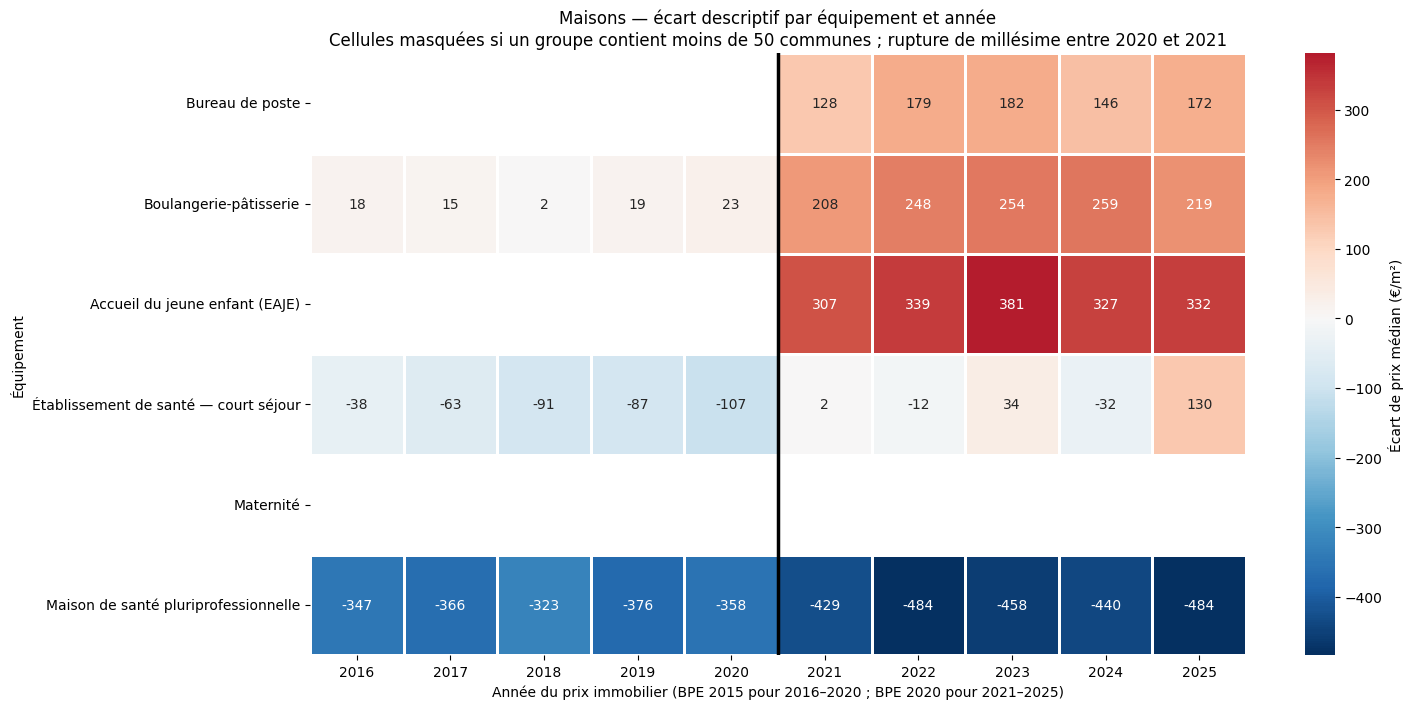

Carte enregistrée : 02_carte_thermique_maisons.png


In [ ]:
chemin_maisons = construire_carte(df, "Maisons", "02_carte_thermique_maisons.png")

### Interprétation — Maisons

Sur la période 2016 - 2025 , les écarts ne suivent pas une évolution uniforme selon les équipements:
-  **Boulangerie-pâtisserie** et  **bureau de poste** présentent des écarts positifs sur les années affichées à partir de 2021.

- **Accueil du jeune enfant (EAJE)** présente également des écarts positifs de 2021 à 2025, autour de +300 à +380 €/m². À l’inverse,

- **Maison de santé pluriprofessionnelle** se distingue par un écart négatif persistant, compris entre environ −320 et −485 €/m² sur la période affichée. L’écart associé aux établissements de santé de court séjour fluctue autour de zéro et ne fait pas apparaître de trajectoire stable. La maternité ne peut pas être interprétée, car les cellules sont masquées en raison des effectifs insuffisants.

**Conclusion :**

**Accueil du jeune enfant (EAJE)** est l’équipement qui présente l’association positive la plus régulière parmi les équipements interprétables depuis 2021 ; la maison de santé pluriprofessionnelle se distingue par l’association négative la plus persistante. Cela permet seulement d’affirmer que, dans les groupes de communes comparés, les prix médians des maisons sont descriptivement plus élevés avec un EAJE et plus faibles avec une maison de santé pluriprofessionnelle. Cela ne prouve pas que ces équipements causent les différences de prix.

**Prudence temporelle :**

la rupture entre 2020 et 2021 correspond aussi au changement de millésime BPE. Les différences de part et d’autre de cette frontière ne peuvent pas être interprétées comme une évolution certaine sans vérification de la comparabilité des millésimes. Les cellules blanches ne représentent pas un écart nul.

```
# Ce texte est au format code
```



## 8. Carte thermique — Appartements

Le code ci-dessous construit la carte des appartements à partir des écarts du CSV et affiche le graphique dans le notebook.

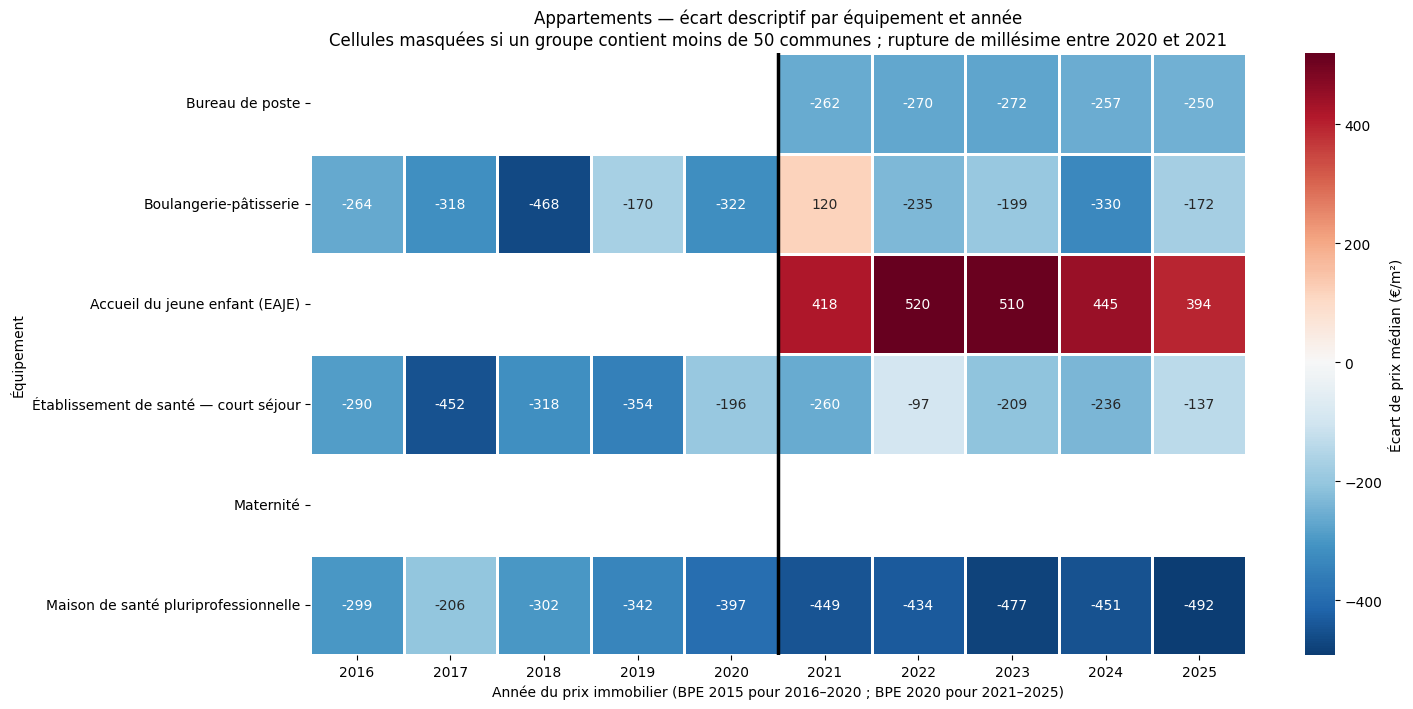

Carte enregistrée : 03_carte_thermique_appartements.png


In [ ]:
chemin_appartements = construire_carte(df, "Appartements", "03_carte_thermique_appartements.png")

### Interpretation — Appartements

Sur la période 2016 - 2025, les associations observées pour les appartements diffèrent parfois de celles des maisons.
- **Accueil du jeune enfant (EAJE)** présente des écarts positifs sur toutes les années affichées, de 2021 à 2025, même si l’écart diminue après son maximum de 2022.
- **Maison de santé pluriprofessionnelle** affiche, elle, un écart négatif chaque année visible de 2016 à 2025, parmi les plus marqués de la carte.
- **Bureau de poste** est associé à des écarts négatifs sur les années visibles à partir de 2021.
- **Boulangerie-pâtisserie** et les **établissements de santé de court séjour** présentent des écarts négatifs la plupart du temps, mais avec des fluctuations et sans trajectoire régulière. La maternité ne peut pas être interprétée : ses cellules sont masquées en raison des effectifs insuffisants.

**Conclusion :**

Les deux équipements qui se démarquent le plus nettement sont **l’EAJE**, associé à des prix médians plus élevés sur la période visible depuis 2021, et **la maison de santé pluriprofessionnelle**, associée à des prix médians plus faibles sur l’ensemble de la période affichée. On peut décrire ces associations dans les communes comparées, mais pas conclure que la présence de ces équipements explique à elle seule les prix observés.

**Prudence temporelle :** la rupture entre 2020 et 2021 correspond au changement de millésime BPE. Les écarts avant/après cette frontière ne sont pas directement interprétables comme une évolution réelle sans contrôle de comparabilité. Les cellules blanches ne représentent pas un écart nul.
